# SE match switching prior with heavy tailed noise

Paper figures 12, 13. Saved results are shown by default; enable the switches below to recompute.

In [1]:
from pathlib import Path
import os
if not Path("WERM").is_dir() and Path("../WERM").is_dir():
    os.chdir("..")
assert Path("WERM").is_dir(), "Open this notebook from the repository root."
from paper_support import show_panels
RUN_EXPERIMENTS = False
REGENERATE_FIGURES = False
REGENERATE_FIGURES = REGENERATE_FIGURES or RUN_EXPERIMENTS

if REGENERATE_FIGURES:
    import numpy as np, pickle, time, logging
    import matplotlib.pyplot as plt
    from IPython.display import display
    main_logger = logging.getLogger("paper")
    Path("figures").mkdir(exist_ok=True)


In [2]:
if RUN_EXPERIMENTS:
    from WERM.config import unif_prior_to_η_φ
    from WERM.config import η_to_ψ
    from WERM.signal_priors import GaussianSignal
    import WERM.model as model
    import importlib
    import WERM.general_fixed_point_eqns as fp
    importlib.reload(fp)
    import WERM.M_est_fixed_point_eqns as M_est
    import WERM.gof
    import WERM.performance_measures
    import WERM.marginals
    import numpy as np
    import jax.numpy as jnp
    import jax
    import numpy.random as nprandom
    import matplotlib.pyplot as plt
    import scipy
    from sklearn import linear_model
    from functools import partial
    from tqdm.auto import tqdm
    import time
    from joblib import Parallel, delayed
    import logging
    from datetime import datetime, timedelta
    import sys
    import pickle
    import os
    random_seed = 42
    MASTER_KEY = jax.random.PRNGKey(random_seed)
    nprandom.seed(random_seed)
    jax.random.PRNGKey(random_seed)

    def setup_logging():
        """Setup comprehensive logging for the simulation"""
        detailed_formatter = logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s', datefmt='%Y-%m-%d %H:%M:%S')
        simple_formatter = logging.Formatter('%(asctime)s - %(message)s', datefmt='%H:%M:%S')
        import os
        log_dir = 'logs'
        if not os.path.exists(log_dir):
            os.makedirs(log_dir)
        main_logger = logging.getLogger('simulation')
        main_logger.setLevel(logging.INFO)
        main_logger.handlers = []
        console_handler = logging.StreamHandler(sys.stdout)
        console_handler.setLevel(logging.INFO)
        console_handler.setFormatter(simple_formatter)
        main_logger.addHandler(console_handler)
        file_handler = logging.FileHandler('logs/WERM_SE_match_huber.log', mode='w')
        file_handler.setLevel(logging.DEBUG)
        file_handler.setFormatter(detailed_formatter)
        main_logger.addHandler(file_handler)
        progress_logger = logging.getLogger('progress')
        progress_logger.setLevel(logging.INFO)
        progress_logger.handlers = []
        progress_handler = logging.FileHandler('logs/WERM_SE_match_huber_progress.log', mode='w')
        progress_handler.setLevel(logging.INFO)
        progress_handler.setFormatter(detailed_formatter)
        progress_logger.addHandler(progress_handler)
        return (main_logger, progress_logger)
    (main_logger, progress_logger) = setup_logging()

    class ProgressTracker:
        """Class to track and log simulation progress"""

        def __init__(self, total_tasks, delta_list, num_trials, logger):
            self.total_tasks = total_tasks
            self.delta_list = delta_list
            self.num_trials = num_trials
            self.logger = logger
            self.start_time = time.time()
            self.completed_tasks = 0
            self.delta_progress = {i: 0 for i in range(len(delta_list))}

        def update(self, delta_idx):
            """Update progress for a completed task"""
            self.completed_tasks += 1
            percent_complete = self.completed_tasks / self.total_tasks * 100
            elapsed_time = time.time() - self.start_time
            if self.completed_tasks > 0:
                avg_time_per_task = elapsed_time / self.completed_tasks
                remaining_tasks = self.total_tasks - self.completed_tasks
                estimated_remaining_time = remaining_tasks * avg_time_per_task
                estimated_completion = datetime.now() + timedelta(seconds=estimated_remaining_time)
                self.logger.info(f"Progress: {self.completed_tasks}/{self.total_tasks} ({percent_complete:.1f}%) | Elapsed: {elapsed_time:.1f}s | Est. remaining: {estimated_remaining_time:.1f}s | Est. completion: {estimated_completion.strftime('%H:%M:%S')}")
            self.delta_progress[delta_idx] += 1
            if self.completed_tasks % max(1, self.total_tasks // 10) == 0 or self.completed_tasks == 1 or self.completed_tasks == self.total_tasks:
                delta_status = []
                for (i, delta) in enumerate(self.delta_list):
                    progress = self.delta_progress[i]
                    delta_status.append(f'δ={delta:.1f}: {progress}/{self.num_trials}')
                self.logger.info('Delta progress: ' + ' | '.join(delta_status))
    progress_tracker = None

    def run_single_trial(params, p, L, noise_std, fractional_chgpt_locations, M, method_configs, B̃):
        """
        Executes a single simulation trial for a given delta, running multiple methods.
        This function is designed to be called in parallel by joblib.
        """
        global progress_tracker
        (i, δ, j) = params
        trial_start_time = time.time()
        progress_logger.info(f'Starting trial {j + 1}/{num_trials} for δ={δ:.1f} (delta_idx={i})')
        n = int(δ * p)
        if fractional_chgpt_locations.size != 0:
            true_chgpt_locations = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)
            C_true = η_to_ψ(true_chgpt_locations(n), n)
        else:
            true_chgpt_locations = lambda n_len: np.array([])
            C_true = np.zeros(n).astype(int)
        Δ = lambda n: int(n / 20)
        Delta_n = int(Δ(n))
        L_is_upper_bound = False
        if Delta_n == 1:
            if L_is_upper_bound:
                pi_i_l = lambda L, l, i: 1 / (L - l + 1) * np.sum([scipy.special.comb(k - 1, l - 1, exact=False) * (i / n) ** (l - 1) * (1 - i / n) ** (k - l) for k in range(l, L + 1)])
            else:
                pi_i_l = lambda L, l, i: scipy.special.comb(L - 1, l - 1, exact=False) * (i / n) ** (l - 1) * (1 - i / n) ** (L - l)
            pi = np.zeros((L, n))
            for l__ in range(L):
                for i__ in range(n):
                    pi[l__, i__] = pi_i_l(L, l__ + 1, i__ + 1)
        else:
            n_small = 100
            Delta_n_small = int(Delta_n * n_small / n)
            if L_is_upper_bound:
                p_l = 1 / L * np.ones(L)
                Lmin = 1
                Lmax = L
            else:
                p_l = None
                Lmin = L
                Lmax = L
            pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small=n_small, n_large=n, p_l=p_l, verbose=False)
        π = pi
        if L == 1:
            π = np.ones((1, n))
        pi_switch = π.copy()
        pi_switch[0, :] = (π[0, :].copy() + π[2, :].copy()) / 2
        pi_switch[2, :] = (π[0, :].copy() + π[2, :].copy()) / 2
        data_gen_start = time.time()
        X = nprandom.normal(0, np.sqrt(1 / n), (n, p))
        X = X @ Sigma_chol.T
        model_q = model.q_linear_model
        ε = np.random.laplace(loc=0.0, scale=1.0, size=(n,)) * noise_std
        ε_theory = np.random.laplace(loc=0.0, scale=1.0, size=(n,)) * noise_std
        B̃ = np.sqrt(δ) * B̃
        Θ = X @ B̃
        y_mapped_fn = jax.vmap(model_q, in_axes=(0, 0, 0))
        y = y_mapped_fn(Θ, C_true, ε)
        data_gen_time = time.time() - data_gen_start
        trial_results = {}
        methods_status = {method_name: False for method_name in method_configs.keys()}
        ρ = 1 / δ * (1 / p) * (B̃.T @ Sigma_chol @ Sigma_chol.T @ B̃)
        for (method_name, method_func_info) in method_configs.items():
            try:
                method_start = time.time()
                current_B̂ = np.zeros((p, L))
                Θ̂_theory = np.zeros((n, L))
                current_corr_list = []
                current_mse_list = []
                current_chgpt_loc = np.array([])
                if method_name == 'ERM-switch':
                    for l_ in range(L):
                        sample_weight = pi_switch[l_, :]
                        empirical_risk = lambda β: jnp.multiply(M((X @ β).flatten(), y.flatten()), sample_weight).sum() / n
                        res = scipy.optimize.minimize(empirical_risk, 0.1 * np.ones(p), jac=jax.grad(empirical_risk), method='L-BFGS-B')
                        β̂ = res.x
                        current_B̂[:, l_] = β̂
                        current_corr_list.append(WERM.norm_sq_corr(β̂, B̃[:, l_]))
                        current_mse_list.append(WERM.MSE(β̂.flatten(), B̃[:, l_]))
                    (opt_chgpt_loc_erm, _) = WERM.gof.chgpt_gof_bf_mem_eff(M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=False, γ=0, batch_size=batch_size, gof_opt_output=True)
                    current_chgpt_loc = opt_chgpt_loc_erm
                elif method_name == 'Theory-switch':
                    (b, ν̃, κ̃, success_status) = fp.compute_single_fixed_point(true_chgpt_locations(n), M, ρ, δ, pi_switch, ε_theory, n, model_q, MASTER_KEY, maxiter=500, lr=0.2)
                    κ̃_sqrt = jnp.linalg.cholesky(κ̃ + 1e-12 * jnp.eye(L))
                    G_sample = nprandom.multivariate_normal(np.zeros((L,)), np.eye(L), size=(p,)) @ κ̃_sqrt.T
                    G_sample_n = nprandom.multivariate_normal(np.zeros((L,)), np.eye(L), size=(n,)) @ κ̃_sqrt.T
                    Z = nprandom.multivariate_normal(np.zeros((L,)), ρ, size=(n,))
                    y_theory = y_mapped_fn(Z, C_true, ε_theory)
                    M_prime = jax.grad(M, argnums=0)
                    M_double_prime = jax.grad(M_prime, argnums=0)
                    for l_ in range(L):
                        β̂_theory = B̃ @ ν̃[:, l_] + δ ** (1 / 2) * np.linalg.inv(Sigma_chol).T @ G_sample[:, l_]
                        current_B̂[:, l_] = β̂_theory
                        current_corr_list.append(WERM.norm_sq_corr(β̂_theory, B̃[:, l_]))
                        current_mse_list.append(WERM.MSE(β̂_theory.flatten(), B̃[:, l_]))
                        sample_weight = pi_switch[l_, :]
                        prox_mapped = lambda z, b, π_i, v: jax.vmap(fp.prox, in_axes=(0, None, 0, 0, None, None))(z, b, π_i, v, M_prime, M_double_prime)
                        Θ̂_theory[:, l_] = prox_mapped(Z @ ν̃[:, l_] + G_sample_n[:, l_], b[l_], sample_weight, y_theory)
                    (opt_chgpt_loc_theory, _) = WERM.gof.chgpt_gof_bf_mem_eff(M, Θ̂_theory, y_theory, n, L, Δ(n), L_is_upper_bound=False, γ=0, batch_size=batch_size, gof_opt_output=True)
                    current_chgpt_loc = opt_chgpt_loc_theory
                elif method_name == 'ERM-unif':
                    for l_ in range(L):
                        sample_weight = π[l_, :]
                        empirical_risk = lambda β: jnp.multiply(M((X @ β).flatten(), y.flatten()), sample_weight).sum() / n
                        res = scipy.optimize.minimize(empirical_risk, 0.1 * np.ones(p), jac=jax.grad(empirical_risk), method='L-BFGS-B')
                        β̂ = res.x
                        current_B̂[:, l_] = β̂
                        current_corr_list.append(WERM.norm_sq_corr(β̂, B̃[:, l_]))
                        current_mse_list.append(WERM.MSE(β̂.flatten(), B̃[:, l_]))
                    (opt_chgpt_loc_erm, _) = WERM.gof.chgpt_gof_bf_mem_eff(M, X @ current_B̂, y, n, L, Δ(n), L_is_upper_bound=False, γ=0, batch_size=batch_size, gof_opt_output=True)
                    current_chgpt_loc = opt_chgpt_loc_erm
                elif method_name == 'Theory-unif':
                    (b, ν̃, κ̃, success_status) = fp.compute_single_fixed_point(true_chgpt_locations(n), M, ρ, δ, π, ε_theory, n, model_q, MASTER_KEY, maxiter=500, lr=0.2)
                    κ̃_sqrt = jnp.linalg.cholesky(κ̃ + 1e-12 * jnp.eye(L))
                    G_sample = nprandom.multivariate_normal(np.zeros((L,)), np.eye(L), size=(p,)) @ κ̃_sqrt.T
                    G_sample_n = nprandom.multivariate_normal(np.zeros((L,)), np.eye(L), size=(n,)) @ κ̃_sqrt.T
                    Z = nprandom.multivariate_normal(np.zeros((L,)), ρ, size=(n,))
                    y_theory = y_mapped_fn(Z, C_true, ε_theory)
                    M_prime = jax.grad(M, argnums=0)
                    M_double_prime = jax.grad(M_prime, argnums=0)
                    for l_ in range(L):
                        β̂_theory = B̃ @ ν̃[:, l_] + δ ** (1 / 2) * np.linalg.inv(Sigma_chol).T @ G_sample[:, l_]
                        current_B̂[:, l_] = β̂_theory
                        current_corr_list.append(WERM.norm_sq_corr(β̂_theory, B̃[:, l_]))
                        current_mse_list.append(WERM.MSE(β̂_theory.flatten(), B̃[:, l_]))
                        sample_weight = π[l_, :]
                        prox_mapped = lambda z, b, π_i, v: jax.vmap(fp.prox, in_axes=(0, None, 0, 0, None, None))(z, b, π_i, v, M_prime, M_double_prime)
                        Θ̂_theory[:, l_] = prox_mapped(Z @ ν̃[:, l_] + G_sample_n[:, l_], b[l_], sample_weight, y_theory)
                    (opt_chgpt_loc_theory, _) = WERM.gof.chgpt_gof_bf_mem_eff(M, Θ̂_theory, y_theory, n, L, Δ(n), L_is_upper_bound=False, γ=0, batch_size=batch_size, gof_opt_output=True)
                    current_chgpt_loc = opt_chgpt_loc_theory
                else:
                    main_logger.warning(f'Method {method_name} not recognized. Skipping.')
                    continue
                method_time = time.time() - method_start
                trial_results[f'runtime_{method_name}'] = method_time
                trial_results[f'corr_{method_name}'] = np.array(current_corr_list)
                trial_results[f'mse_{method_name}'] = np.array(current_mse_list)
                trial_results[f'haus_{method_name}'] = 1 / n * WERM.performance_measures.hausdorff(current_chgpt_loc, true_chgpt_locations(n))
                trial_results[f'size_{method_name}'] = len(current_chgpt_loc[current_chgpt_loc != -1])
                trial_results[f'chgpts_{method_name}'] = current_chgpt_loc.copy()
                methods_status[method_name] = True
            except Exception as e:
                main_logger.error(f'Trial {j + 1} for δ={δ:.1f}: {method_name} failed with error: {e}', exc_info=True)
                trial_results[f'runtime_{method_name}'] = np.nan
                trial_results[f'corr_{method_name}'] = np.full(L, np.nan)
                trial_results[f'mse_{method_name}'] = np.full(L, np.nan)
                trial_results[f'haus_{method_name}'] = np.nan
                trial_results[f'size_{method_name}'] = np.nan
                trial_results[f'chgpts_{method_name}'] = np.array([])
                methods_status[method_name] = False
        trial_results['n'] = n
        trial_results['true_chgpts'] = true_chgpt_locations(n).copy()
        trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
        trial_results['methods_status'] = methods_status
        trial_total_time = time.time() - trial_start_time
        log_message_parts = [f'Completed trial {j + 1} for δ={δ:.1f}: ', f'Total={trial_total_time:.1f}s (Data={data_gen_time:.1f}s)']
        for method_name in method_configs.keys():
            status_str = 'OK' if methods_status[method_name] else 'FAIL'
            runtime_str = f"{trial_results[f'runtime_{method_name}']:.1f}s" if f'runtime_{method_name}' in trial_results and (not np.isnan(trial_results[f'runtime_{method_name}'])) else 'N/A'
            log_message_parts.append(f'{method_name}={status_str} ({runtime_str})')
        progress_logger.info(' '.join(log_message_parts))
        if progress_tracker:
            progress_tracker.update(i)
        return (i, j, trial_results)
    main_logger.info('Starting WERM Simulation with parallel execution and enhanced logging')
    main_logger.info('=' * 80)
    p = 800
    L = 3
    noise_std = np.sqrt(0.1)
    δ_list = np.arange(2.25, 3.51, 0.25)
    num_trials = 10
    fractional_chgpt_locations = np.array([0.3, 0.8])
    n_jobs = 45

    def M(u, v, epsilon=1.35):
        residual = u - v
        abs_residual = jnp.abs(residual)
        condition = abs_residual <= epsilon
        squared_loss = 0.5 * jnp.square(residual)
        linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
        return jnp.where(condition, squared_loss, linear_loss)
    κ = 0.3
    B̃_cov = κ ** 2 * np.eye(L)
    B̃_cov[0, 2] = 0.975 * κ ** 2
    B̃_cov[2, 0] = 0.975 * κ ** 2
    B̃_cov[0, 1] = 0.1 * κ ** 2
    B̃_cov[1, 0] = 0.1 * κ ** 2
    B̃_cov[1, 2] = 0.1 * κ ** 2
    B̃_cov[2, 1] = 0.1 * κ ** 2
    signal_prior = GaussianSignal(B̃_cov)
    B̃ = signal_prior.sample(p)
    r_s = 0.1
    AR1 = np.fromfunction(lambda i, j: r_s ** np.abs(i - j), (p, p))
    Sigma = AR1
    Sigma_chol = np.linalg.cholesky(Sigma + 1e-12 * np.eye(p))
    batch_size = 4096 * 6
    methods_to_evaluate = [{'name': 'ERM-switch', 'label': '\\textbf{ERM-switch}', 'color': '#EE7733', 'marker': 'o', 'linestyle': '-'}, {'name': 'Theory-switch', 'label': '\\textbf{Theory-switch}', 'color': '#0077BB', 'marker': 'D', 'linestyle': '-.'}, {'name': 'ERM-unif', 'label': '\\textbf{ERM-unif}', 'color': '#EE7733', 'marker': 'x', 'linestyle': '--'}, {'name': 'Theory-unif', 'label': '\\textbf{Theory-unif}', 'color': '#0077BB', 'marker': '^', 'linestyle': ':'}]
    method_configs = {method['name']: method for method in methods_to_evaluate}
    method_names_list = [m['name'] for m in methods_to_evaluate]
    main_logger.info(f'Simulation Parameters:')
    main_logger.info(f' p (features): {p}')
    main_logger.info(f' L (signals): {L}')
    main_logger.info(f' noise_std: {noise_std}')
    main_logger.info(f' δ_list: {δ_list}')
    main_logger.info(f' num_trials: {num_trials}')
    main_logger.info(f' fractional_chgpt_locations: {fractional_chgpt_locations}')
    main_logger.info(f' n_jobs: {n_jobs}')
    main_logger.info(f' Loss function: Least Squares')
    main_logger.info(f' Methods to evaluate: {method_names_list}')
    main_logger.info(f' Total tasks: {len(δ_list) * num_trials}')
    results = {'successful_trials': {method['name']: np.zeros(len(δ_list), dtype=int) for method in methods_to_evaluate}, 'true_chgpts': [], 'n_values': [], 'delta_values': []}
    for method in methods_to_evaluate:
        method_name = method['name']
        results[f'corr_{method_name}'] = np.full((len(δ_list), num_trials, L), np.nan)
        results[f'mse_{method_name}'] = np.full((len(δ_list), num_trials, L), np.nan)
        results[f'haus_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
        results[f'size_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
        results[f'runtime_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
        results[f'chgpts_{method_name}'] = []
    tasks = [(i, δ, j) for (i, δ) in enumerate(δ_list) for j in range(num_trials)]
    main_logger.info('=' * 80)
    main_logger.info(f'Starting {len(tasks)} simulation trials')
    main_logger.info(f"Using {(n_jobs if n_jobs != -1 else 'all available')} CPU cores")
    single_trial_estimate = 20.0
    total_estimated_time = len(tasks) * single_trial_estimate / (n_jobs if n_jobs > 0 else 4)
    estimated_completion = datetime.now() + timedelta(seconds=total_estimated_time)
    main_logger.info(f'Estimated total time: {total_estimated_time / 60:.1f} minutes')
    main_logger.info(f"Estimated completion: {estimated_completion.strftime('%Y-%m-%d %H:%M:%S')}")
    main_logger.info('=' * 80)
    progress_tracker = ProgressTracker(len(tasks), δ_list, num_trials, main_logger)
    simulation_start_time = time.time()
    try:
        parallel_results = Parallel(n_jobs=n_jobs, verbose=0)((delayed(run_single_trial)(params=task, p=p, L=L, noise_std=noise_std, fractional_chgpt_locations=fractional_chgpt_locations, M=M, method_configs=method_configs, B̃=B̃) for task in tqdm(tasks, desc='Running simulation trials', ncols=100, leave=True)))
        simulation_end_time = time.time()
        total_simulation_time = simulation_end_time - simulation_start_time
        main_logger.info('=' * 80)
        main_logger.info(f'Simulation completed successfully!')
        main_logger.info(f'Total simulation time: {total_simulation_time / 60:.2f} minutes')
        main_logger.info(f'Average time per trial: {total_simulation_time / len(tasks):.2f} seconds')
        main_logger.info('=' * 80)
    except Exception as e:
        main_logger.error(f'Simulation failed with error: {str(e)}', exc_info=True)
        raise
    main_logger.info('Aggregating results...')
    aggregation_start_time = time.time()
    for (result_idx, (i, j, trial_result)) in enumerate(parallel_results):
        for method_obj in methods_to_evaluate:
            method_name = method_obj['name']
            if trial_result['methods_status'][method_name]:
                results[f'corr_{method_name}'][i, j, :] = trial_result[f'corr_{method_name}']
                results[f'mse_{method_name}'][i, j, :] = trial_result[f'mse_{method_name}']
                results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
                results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
                results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
                results['successful_trials'][method_name][i] += 1
            results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}']))
        results['true_chgpts'].append((i, trial_result['true_chgpts']))
        results['n_values'].append((i, trial_result['n']))
        results['delta_values'].append((i, δ_list[i]))
    aggregation_time = time.time() - aggregation_start_time
    main_logger.info(f'Results aggregation completed in {aggregation_time:.2f} seconds')
    main_logger.info('=' * 40)
    main_logger.info('SIMULATION SUMMARY STATISTICS')
    main_logger.info('=' * 40)
    for (i, delta) in enumerate(δ_list):
        main_logger.info(f'δ = {delta:.1f}:')
        for method_obj in methods_to_evaluate:
            method_name = method_obj['name']
            avg_corr = np.nanmean(results[f'corr_{method_name}'][i, :, :])
            std_corr = np.nanstd(results[f'corr_{method_name}'][i, :, :])
            avg_mse = np.nanmean(results[f'mse_{method_name}'][i, :, :])
            std_mse = np.nanstd(results[f'mse_{method_name}'][i, :, :])
            avg_haus = np.nanmean(results[f'haus_{method_name}'][i, :])
            std_haus = np.nanstd(results[f'haus_{method_name}'][i, :])
            avg_size = np.nanmean(results[f'size_{method_name}'][i, :])
            std_size = np.nanstd(results[f'size_{method_name}'][i, :])
            avg_runtime = np.nanmean(results[f'runtime_{method_name}'][i, :])
            std_runtime = np.nanstd(results[f'runtime_{method_name}'][i, :])
            num_success = results['successful_trials'][method_name][i]
            main_logger.info(f' {method_name} - Successful Trials: {num_success}/{num_trials}')
            main_logger.info(f' {method_name} - Avg Norm Sq Corr: {avg_corr:.4f} ± {std_corr:.4f}')
            main_logger.info(f' {method_name} - Avg MSE: {avg_mse:.4f} ± {std_mse:.4f}')
            main_logger.info(f' {method_name} - Avg Hausdorff: {avg_haus:.4f} ± {std_haus:.4f}')
            main_logger.info(f' {method_name} - Avg Size: {avg_size:.2f} ± {std_size:.2f}')
            main_logger.info(f' {method_name} - Avg Runtime: {avg_runtime:.2f}s ± {std_runtime:.2f}s')
        main_logger.info('')
    plt.rcParams.update({'font.size': 14, 'font.family': 'serif', 'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'], 'text.usetex': True, 'axes.linewidth': 1.5, 'axes.labelsize': 16, 'axes.titlesize': 18, 'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14, 'legend.frameon': True, 'legend.fancybox': False, 'legend.edgecolor': 'black', 'legend.framealpha': 0.95, 'lines.linewidth': 3.0, 'lines.markersize': 8, 'figure.dpi': 72, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.1})
    main_logger.info('Creating publication-ready plots...')
    plotting_start_time = time.time()
    TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377', '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33']
    PAL = TOL_VIBRANT
    for (i, method_obj) in enumerate(methods_to_evaluate):
        method_obj['color'] = PAL[i % len(PAL)]

    def get_asymmetric_errors(data):
        """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
        means = np.nanmean(data, axis=0)
        p25 = np.nanpercentile(data, 25, axis=0)
        p75 = np.nanpercentile(data, 75, axis=0)
        lower_errors = np.abs(means - p25)
        upper_errors = np.abs(p75 - means)
        return [lower_errors, upper_errors]

    def plot_with_asymmetric_errors_publication_per_signal(L):
        """
        Plots with asymmetric error bars, showing each signal (l) separately for corr and mse.
        """
        (fig, axs) = plt.subplots(1, 4, figsize=(24, 6))
        fig.suptitle('\\textbf{WERM Performance Analysis: Per Signal}', fontsize=20, y=0.98)
        plot_colors = [method['color'] for method in methods_to_evaluate]
        plot_markers = [method['marker'] for method in methods_to_evaluate]
        plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]
        metrics_to_plot = [('corr', 'Normalized Squared Correlation', '\\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)), ('mse', 'Mean Squared Error', '\\textbf{(b) Signal Estimation: MSE}', None), ('haus', 'Hausdorff Distance / $n$', '\\textbf{(c) Changepoint Location Error}', (0, 0.5)), ('size', 'Number of Changepoints', '\\textbf{(d) Changepoint Set Size}', (0, L + 2))]
        for (ax_idx, (metric_key, ylabel, title, ylim)) in enumerate(metrics_to_plot):
            ax = axs[ax_idx]
            for (i, method_obj) in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                if metric_key in ['corr', 'mse']:
                    for l_idx in range(L):
                        data_l = results[f'{metric_key}_{method_name}'][:, :, l_idx]
                        if np.all(np.isnan(data_l)):
                            main_logger.warning(f'No successful trials for {method_name} (signal {l_idx + 1}, {metric_key}). Skipping plot.')
                            continue
                        means = np.nanmean(data_l, axis=1)
                        errors = get_asymmetric_errors(data_l)
                        ax.errorbar(δ_list, means, yerr=errors, label=f"{method_obj['label']} ($\\ell={l_idx + 1}$)", marker=plot_markers[i], ls=plot_linestyles[i], color=plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[i], capsize=4, capthick=2, markersize=8, linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
                else:
                    data = results[f'{metric_key}_{method_name}']
                    if np.all(np.isnan(data)):
                        main_logger.warning(f'No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.')
                        continue
                    means = np.nanmean(data, axis=1)
                    errors = get_asymmetric_errors(data)
                    ax.errorbar(δ_list, means, yerr=errors, label=method_obj['label'], marker=plot_markers[i], ls=plot_linestyles[i], color=plot_colors[i], capsize=4, capthick=2, markersize=8, linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
            if metric_key == 'size':
                ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-', linewidth=2.5, alpha=0.8, label='\\textbf{True Size}')
            if ylim:
                ax.set_ylim(ylim)
            else:
                ax.set_ylim(bottom=0)
            ax.set_xlabel('$\\delta = n/p$', fontsize=18)
            ax.set_ylabel(ylabel, fontsize=18)
            ax.set_title(title, fontsize=18, pad=15)
            ax.set_xticks(δ_list[::2])
            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
        (handles, labels_leg) = axs[0].get_legend_handles_labels()
        fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=len(methods_to_evaluate) * L + (1 if 'size' in [m[0] for m in metrics_to_plot] else 0), fontsize=12, frameon=True, edgecolor='black', framealpha=0.95)
        plt.tight_layout(rect=[0, 0.08, 1, 0.95])

    def plot_with_confidence_bands_publication_per_signal(L):
        """
        Plots with confidence bands, showing each signal (l) separately for corr and mse.
        """
        (fig, axs) = plt.subplots(1, 4, figsize=(24, 6))
        fig.suptitle('\\textbf{WERM Performance Analysis: Confidence Intervals Per Signal}', fontsize=20, y=0.98)
        plot_colors = [method['color'] for method in methods_to_evaluate]
        metrics_to_plot = [('corr', 'Normalized Squared Correlation', '\\textbf{(a) Signal Estimation: Norm Sq Corr}', (0, 1.05)), ('mse', 'Mean Squared Error', '\\textbf{(b) Signal Estimation: MSE}', None), ('haus', 'Hausdorff Distance / $n$', '\\textbf{(c) Changepoint Location Error}', (0, 0.5)), ('size', 'Number of Changepoints', '\\textbf{(d) Changepoint Set Size}', (0, L + 2))]
        for (ax_idx, (metric_key, ylabel, title, ylim)) in enumerate(metrics_to_plot):
            ax = axs[ax_idx]
            for (method_idx, method_obj) in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                if metric_key in ['corr', 'mse']:
                    for l_idx in range(L):
                        data_l = results[f'{metric_key}_{method_name}'][:, :, l_idx]
                        if np.all(np.isnan(data_l)):
                            main_logger.warning(f'No successful trials for {method_name} (signal {l_idx + 1}, {metric_key}). Skipping plot.')
                            continue
                        means = np.nanmean(data_l, axis=1)
                        p10 = np.nanpercentile(data_l, 10, axis=1)
                        p90 = np.nanpercentile(data_l, 90, axis=1)
                        p10 = np.minimum(p10, means)
                        p90 = np.maximum(p90, means)
                        current_color = plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx]
                        ax.fill_between(δ_list, p10, p90, color=current_color, alpha=0.15, zorder=1)
                        ax.plot(δ_list, means, color=current_color, linewidth=4, marker='o', markersize=9, label=f"{method_obj['label']} ($\\ell={l_idx + 1}$)", zorder=3, markeredgewidth=2, markeredgecolor='white')
                else:
                    data = results[f'{metric_key}_{method_name}']
                    if np.all(np.isnan(data)):
                        main_logger.warning(f'No successful trials for {method_name} ({metric_key}). Skipping plot for this metric.')
                        continue
                    means = np.nanmean(data, axis=1)
                    p10 = np.nanpercentile(data, 10, axis=1)
                    p90 = np.nanpercentile(data, 90, axis=1)
                    p10 = np.minimum(p10, means)
                    p90 = np.maximum(p90, means)
                    ax.fill_between(δ_list, p10, p90, color=plot_colors[method_idx], alpha=0.15, zorder=1)
                    ax.plot(δ_list, means, color=plot_colors[method_idx], linewidth=4, marker='o', markersize=9, label=method_obj['label'], zorder=3, markeredgewidth=2, markeredgecolor='white')
            if metric_key == 'size':
                ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-', linewidth=3, alpha=0.8, label='\\textbf{True Size}', zorder=2)
            if ylim:
                ax.set_ylim(ylim)
            elif metric_key in ['mse', 'runtime']:
                ax.set_ylim(bottom=0)
            ax.set_xlabel('$\\delta = n/p$', fontsize=18)
            ax.set_ylabel(ylabel, fontsize=18)
            ax.set_title(title, fontsize=18, pad=15)
            ax.set_xticks(δ_list[::2])
            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
        (handles, labels_leg) = axs[0].get_legend_handles_labels()
        fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=len(methods_to_evaluate) * L + (1 if 'size' in [m[0] for m in metrics_to_plot] else 0), fontsize=12, frameon=True, edgecolor='black', framealpha=0.95)
        plt.tight_layout(rect=[0, 0.08, 1, 0.95])

    def plot_with_boxplots_publication_per_signal(L):
        """
        Creates box plots, showing each signal (l) separately for corr and mse.
        """
        (fig, axs) = plt.subplots(1, 4, figsize=(24, 6))
        fig.suptitle('\\textbf{WERM Performance Analysis: Distribution Comparison Per Signal}', fontsize=20, y=0.98)
        plot_colors = [method['color'] for method in methods_to_evaluate]
        metrics_to_plot = [('corr', 'Normalized Squared Correlation', '\\textbf{(a) Signal Estimation: Norm Sq Corr}'), ('mse', 'Mean Squared Error', '\\textbf{(b) Signal Estimation: MSE}'), ('haus', 'Hausdorff Distance / $n$', '\\textbf{(c) Changepoint Location Error}'), ('size', 'Number of Changepoints', '\\textbf{(d) Changepoint Set Size}')]
        for (ax_idx, (metric_key, ylabel, title)) in enumerate(metrics_to_plot):
            ax = axs[ax_idx]
            spacing = len(methods_to_evaluate) * L + 1
            if metric_key not in ['corr', 'mse']:
                spacing = len(methods_to_evaluate) + 1
            for (delta_idx, delta) in enumerate(δ_list):
                box_data = []
                box_positions = []
                box_colors = []
                for (method_idx, method_obj) in enumerate(methods_to_evaluate):
                    method_name = method_obj['name']
                    if metric_key in ['corr', 'mse']:
                        for l_idx in range(L):
                            data_l = results[f'{metric_key}_{method_name}'][delta_idx, :, l_idx]
                            valid_data = data_l[~np.isnan(data_l)]
                            if len(valid_data) > 0:
                                box_data.append(valid_data)
                                position = delta_idx * spacing + (method_idx * L + l_idx)
                                box_positions.append(position)
                                box_colors.append(plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx])
                            else:
                                main_logger.warning(f'No valid data for {method_name} (signal {l_idx + 1}) for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.')
                    else:
                        data = results[f'{metric_key}_{method_name}'][delta_idx, :]
                        valid_data = data[~np.isnan(data)]
                        if len(valid_data) > 0:
                            box_data.append(valid_data)
                            box_positions.append(delta_idx * spacing + method_idx)
                            box_colors.append(plot_colors[method_idx])
                        else:
                            main_logger.warning(f'No valid data for {method_name} for delta {delta:.1f} ({metric_key}). Skipping box plot for this point.')
                if len(box_data) > 0:
                    bp = ax.boxplot(box_data, positions=box_positions, widths=0.7, patch_artist=True, showfliers=True, flierprops=dict(marker='o', markersize=4, alpha=0.6), medianprops=dict(color='white', linewidth=2.5), boxprops=dict(linewidth=1.5), whiskerprops=dict(linewidth=1.5), capprops=dict(linewidth=1.5))
                    for (patch, color) in zip(bp['boxes'], box_colors):
                        patch.set_facecolor(color)
                        patch.set_alpha(0.8)
                        patch.set_edgecolor('black')
            if metric_key in ['corr', 'mse']:
                delta_positions = [i * spacing + (len(methods_to_evaluate) * L - 1) / 2 for i in range(len(δ_list))]
            else:
                delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(δ_list))]
            ax.set_xticks(delta_positions[::2])
            ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
            ax.set_xlabel('$\\delta = n/p$', fontsize=18)
            ax.set_ylabel(ylabel, fontsize=18)
            ax.set_title(title, fontsize=18, pad=15)
            legend_elements = []
            if metric_key in ['corr', 'mse']:
                for (method_idx, method_obj) in enumerate(methods_to_evaluate):
                    for l_idx in range(L):
                        current_color = plt.cm.viridis(l_idx / L) if L > 1 else plot_colors[method_idx]
                        legend_elements.append(plt.Rectangle((0, 0), 1, 1, facecolor=current_color, alpha=0.8, edgecolor='black', linewidth=1.5, label=f"{method_obj['label']} ($\\ell={l_idx + 1}$)"))
            else:
                legend_elements = [plt.Rectangle((0, 0), 1, 1, facecolor=plot_colors[i], alpha=0.8, edgecolor='black', linewidth=1.5, label=plot_labels[i]) for i in range(len(methods_to_evaluate))]
            if metric_key == 'size':
                ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-', linewidth=3, alpha=0.8, label='\\textbf{True Size}')
                legend_elements.append(plt.Line2D([0], [0], color='black', lw=3, linestyle='-', label='\\textbf{True Size}'))
            ax.legend(handles=legend_elements, loc='upper left', fontsize=10, frameon=True, edgecolor='black', framealpha=0.95, ncol=1 + (L - 1 if metric_key in ['corr', 'mse'] else 0))
            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    main_logger.info('Generating plots...')
    plot_with_asymmetric_errors_publication_per_signal(L)
    plot_with_confidence_bands_publication_per_signal(L)
    plot_with_boxplots_publication_per_signal(L)
    plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, method_names_list)
    plotting_time = time.time() - plotting_start_time
    main_logger.info(f'Publication-ready plotting completed in {plotting_time:.2f} seconds')
    method_names_for_filename = '_'.join((method['name'] for method in methods_to_evaluate))
    filename = f"results/WERM_SE_match_est_switchvsunif_huber_laplace_nopinorm_{method_names_for_filename}_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}_deltas_{'_'.join(map(str, map(int, δ_list)))}.pkl"
    results_dir = 'results'
    if not os.path.exists(results_dir):
        os.makedirs(results_dir)
    with open(filename, 'wb') as f:
        pickle.dump({'results': results, 'params': {'p': p, 'L': L, 'noise_std': noise_std, 'δ_list': δ_list, 'num_trials': num_trials, 'fractional_chgpt_locations': fractional_chgpt_locations, 'n_jobs': n_jobs, 'successful_trials_counts': results['successful_trials'], 'methods_evaluated': methods_to_evaluate, 'random_seed': random_seed, 'Sigma': Sigma, 'B_tilde': B̃}}, f)
    main_logger.info(f'Results saved to {filename}')


## Plot WERM unif vs switch (algorithm only), with Laplace noise

In [3]:
if REGENERATE_FIGURES:
    import importlib
    import sys
    import numpy as np
    import time
    import matplotlib
    import gc
    from scipy.stats import gaussian_kde
    import matplotlib.pyplot as plt
    import random
    import pickle
    try:
        import matplotlib.pyplot as plt
        plt.close('all')
    except:
        pass
    gc.collect()
    matplotlib.use('pgf')
    import matplotlib.pyplot as plt
    plt.rcParams.update({'pgf.texsystem': 'pdflatex', 'pgf.preamble': '\n        \\usepackage{amsmath}\n        \\usepackage{amsfonts}\n        \\usepackage{amssymb}\n        \\usepackage{siunitx}\n    ', 'font.size': 14, 'font.family': 'serif', 'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'], 'text.usetex': True, 'axes.linewidth': 1.5, 'axes.labelsize': 16, 'axes.titlesize': 18, 'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14, 'legend.frameon': True, 'legend.fancybox': False, 'legend.edgecolor': 'black', 'legend.framealpha': 0.95, 'lines.linewidth': 4.0, 'lines.markersize': 8, 'figure.dpi': 72, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.1})
    try:
        main_logger.info('Creating publication-ready plots...')
    except NameError:
        pass
    plotting_start_time = time.time()
    TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377', '#CC3311', '#009988', '#BBBBBB']
    PAL = TOL_VIBRANT
    filename = 'WERM_SE_match_est_switchvsunif_huber_laplace_nopinorm_ERM-switch_Theory-switch_ERM-unif_Theory-unif_p800_L3_noisestd0.31622776601683794_seed42_deltas_2_2_2_3_3_3'
    filename_extension = '.pkl'
    _example_filename = 'results/' + filename + filename_extension
    with open(_example_filename, 'rb') as f:
        data = pickle.load(f)
    results = data['results']
    params = data['params']
    p = params['p']
    L = params['L']
    noise_std = params['noise_std']
    δ_list = params['δ_list']
    fractional_chgpt_locations = params['fractional_chgpt_locations']
    n_jobs = params['n_jobs']
    methods_to_evaluate = params['methods_evaluated']
    random_seed = params.get('random_seed', None)
    methods_to_evaluate = [method for method in methods_to_evaluate if 'Theory' not in method['name']]
    for method in methods_to_evaluate:
        if method['name'] == 'ERM-switch':
            method['label'] = '\\textbf{WERM Alt. Signal}'
        elif method['name'] == 'ERM-unif':
            method['label'] = '\\textbf{WERM Unif.}'
        elif method['name'] == 'Theory-switch':
            method['label'] = '\\textbf{Theory-Switch}'
        elif method['name'] == 'Theory-unif':
            method['label'] = '\\textbf{Theory-Unif}'
        else:
            method['label'] = f"\\textbf{{{method['name'].capitalize()}}}"
    method_names_list = [method['name'] for method in methods_to_evaluate]

    def get_asymmetric_errors(data):
        """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
        means = np.nanmean(data, axis=1)
        p25 = np.nanpercentile(data, 25, axis=1)
        p75 = np.nanpercentile(data, 75, axis=1)
        lower_errors = np.abs(means - p25)
        upper_errors = np.abs(p75 - means)
        return [lower_errors, upper_errors]

    def plot_with_asymmetric_errors_publication(plot_type='all'):
        """ plot_type is either: 'all', 'location', 'size', 'runtime'. """
        if plot_type == 'all':
            (fig, axs) = plt.subplots(1, 3, figsize=(20, 6))
            fig.suptitle('\\textbf{Weighted ERM Performance Analysis}', fontsize=20, y=0.98)
        else:
            (fig, axs) = plt.subplots(1, 1, figsize=(5.6, 3.2))
        methods = method_names_list
        colors = PAL[:len(methods)]
        markers = ['o', 's', 'D', '^', 'v', '<', '>', 'P', '*']
        linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1)), (0, (5, 1))]
        labels = [method['label'] for method in methods_to_evaluate]
        if plot_type == 'all' or plot_type == 'location':
            if plot_type == 'all':
                ax = axs[0]
            elif plot_type == 'location':
                ax = axs
            for (i, method_name) in enumerate(methods):
                data = results[f'haus_{method_name}']
                data = np.where(np.isinf(data), np.nan, data)
                means = np.nanmean(data, axis=1)
                errors = get_asymmetric_errors(data)
                ax.errorbar(δ_list, means, yerr=errors, label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)], color=colors[i], capsize=4, capthick=2, markersize=8, linewidth=3.5, markeredgewidth=2, markeredgecolor='white', alpha=0.8)
            ax.set_ylim((0, 0.25))
            ax.set_xlabel('$\\delta = n/p$', fontsize=18)
            ax.set_ylabel('Hausdorff Dist. / $n$', fontsize=18)
            if plot_type == 'all':
                ax.set_title('\\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)
            ax.set_xticks(δ_list[::2])
            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
        if plot_type == 'all' or plot_type == 'size':
            if plot_type == 'all':
                ax = axs[1]
            elif plot_type == 'size':
                ax = axs
            for (i, method_name) in enumerate(methods):
                data = results[f'size_{method_name}']
                means = np.nanmean(data, axis=1)
                errors = get_asymmetric_errors(data)
                ax.errorbar(δ_list, means, yerr=errors, label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)], color=colors[i], capsize=4, capthick=2, markersize=8, linewidth=3.5, markeredgewidth=2, markeredgecolor='white', alpha=0.8)
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-', linewidth=2.5, alpha=0.8, label='\\textbf{True Size}')
            ax.set_ylim((0, L + 2))
            ax.set_xlabel('$\\delta = n/p$', fontsize=18)
            ax.set_ylabel('Number of Chgpts', fontsize=18)
            if plot_type == 'all':
                ax.set_title('\\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)
            ax.set_xticks(δ_list[::2])
            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
        if plot_type == 'all' or plot_type == 'runtime':
            if plot_type == 'all':
                ax = axs[2]
            elif plot_type == 'runtime':
                ax = axs
            for (i, method_name) in enumerate(methods):
                data = results[f'runtime_{method_name}']
                means = np.nanmean(data, axis=1)
                errors = get_asymmetric_errors(data)
                ax.errorbar(δ_list, means, yerr=errors, label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)], color=colors[i], capsize=4, capthick=2, markersize=8, linewidth=3.5, markeredgewidth=2, markeredgecolor='white', alpha=0.8)
            ax.set_ylim(bottom=0)
            ax.set_xlabel('$\\delta = n/p$', fontsize=18)
            ax.set_ylabel('Runtime (s)', fontsize=18)
            if plot_type == 'all':
                ax.set_title('\\textbf{(c) Method Runtime}', fontsize=18, pad=15)
            ax.set_xticks(δ_list[::2])
            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
        if plot_type == 'all':
            (handles, labels_leg) = axs[1].get_legend_handles_labels()
            if plot_type != 'location':
                fig.legend(handles, labels_leg, loc='upper left', bbox_to_anchor=(0.5, 0.02), ncol=len(methods) + 1, fontsize=16, frameon=True, edgecolor='black', framealpha=0.95, fancybox=True)
            plt.tight_layout(rect=[0, 0.08, 1, 0.95])
        else:
            ax.legend(loc='best', prop={'size': 16}, fancybox=True, framealpha=0.4)
            fig.tight_layout()
        return (fig, axs)

    def plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names=['ext']):
        """
        Publication-ready changepoint location histograms
        Updated to use method_names_list and method_labels from methods_to_evaluate.
        """
        method_names_map = {method['name']: method['label'] for method in methods_to_evaluate}
        method_colors_map = {method['name']: PAL[i % len(PAL)] for (i, method) in enumerate(methods_to_evaluate)}
        current_methods = [method for method in methods_to_evaluate if method['name'] in methods_to_plot_names]
        current_method_names = [method['name'] for method in current_methods]
        selected_deltas_idx = list(range(len(δ_list)))[::2]
        selected_deltas = δ_list[::2]
        (fig, axes) = plt.subplots(len(selected_deltas), len(current_methods), figsize=(6 * len(current_methods), 4 * len(selected_deltas)))
        if len(selected_deltas) == 1 and len(current_methods) == 1:
            axes = np.array([[axes]])
        elif len(current_methods) == 1:
            axes = axes.reshape(-1, 1)
        elif len(selected_deltas) == 1:
            axes = axes.reshape(1, -1)
        fig.patch.set_facecolor('white')
        for (row, (delta_idx, delta)) in enumerate(zip(selected_deltas_idx, selected_deltas)):
            n = int(delta * p)
            for (col, method_name) in enumerate(current_method_names):
                ax = axes[row, col]
                ax.set_facecolor('white')
                all_chgpts = []
                chgpts_data_for_method = results.get(f'chgpts_{method_name}', [])
                for (res_delta_idx, chgpts_list) in chgpts_data_for_method:
                    if res_delta_idx == delta_idx:
                        for chgpts in chgpts_list:
                            if hasattr(chgpts, '__len__') and len(chgpts) > 0:
                                chgpts_array = np.array(chgpts)
                                valid_chgpts = chgpts_array[chgpts_array != -1]
                                for chgpt in valid_chgpts:
                                    fractional_chgpt = chgpt / n
                                    all_chgpts.append(fractional_chgpt)
                            elif np.isscalar(chgpts) and chgpts != -1:
                                fractional_chgpt = chgpts / n
                                all_chgpts.append(fractional_chgpt)
                if len(all_chgpts) > 0:
                    (counts, bins, patches) = ax.hist(all_chgpts, bins=25, alpha=0.8, color=method_colors_map[method_name], density=True, edgecolor='white', linewidth=1.5)
                else:
                    ax.text(0.5, 0.5, '\\textit{No changepoints detected}', transform=ax.transAxes, ha='center', va='center', fontsize=14, alpha=0.7, style='italic')
                for (i, true_chgpt) in enumerate(fractional_chgpt_locations):
                    ax.axvline(x=true_chgpt, color='black', linestyle='--', linewidth=3, alpha=0.9, zorder=10, label='\\textbf{True Chgpts}' if i == 0 else '')
                ax.set_xlim(0, 1)
                if row == len(selected_deltas) - 1:
                    ax.set_xlabel('Fractional Location ($\\hat{\\mathbf{\\eta}}/n$)', fontsize=16)
                if col == 0:
                    ax.set_ylabel('Density', fontsize=16)
                if row == 0:
                    ax.set_title(f'{method_names_map[method_name]}', fontsize=18, pad=15)
                if col == len(current_methods) - 1:
                    ax.text(1.02, 0.5, f'$n = {n}$', transform=ax.transAxes, rotation=90, verticalalignment='center', fontsize=14, fontweight='bold')
                ax.tick_params(axis='both', which='major', width=1.5, length=6)
                ax.spines['top'].set_visible(False)
                ax.spines['right'].set_visible(False)
                ax.spines['left'].set_linewidth(1.5)
                ax.spines['bottom'].set_linewidth(1.5)
                if row == 0 and col == 0 and (len(all_chgpts) > 0):
                    legend = ax.legend(loc='upper right', fontsize=12, frameon=True, edgecolor='black', framealpha=0.95, fancybox=True)
        plt.tight_layout(rect=[0, 0.03, 1, 0.97])
        return (fig, axes)
    (fig_loc, axs_loc) = plot_with_asymmetric_errors_publication(plot_type='location')
    method_names_for_filename = '_'.join((method['name'] for method in methods_to_evaluate))
    fig_loc.savefig('figures/' + filename + '_location.pdf', dpi=300, bbox_inches='tight')
    fig_loc.savefig('figures/' + filename + '_location.pgf', dpi=300, bbox_inches='tight')
    (fig_size, axs_size) = plot_with_asymmetric_errors_publication(plot_type='size')
    (fig_rt, axs_rt) = plot_with_asymmetric_errors_publication(plot_type='runtime')
    (fig_hist, axs_hist) = plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names=method_names_list)
    plotting_time = time.time() - plotting_start_time
    try:
        main_logger.info(f'Publication-ready plotting completed in {plotting_time:.2f} seconds')
    except NameError:
        pass
    plt.close("all")


## Plot switching prior theory match with Laplace noise

In [4]:
if REGENERATE_FIGURES:
    import importlib
    import sys
    import numpy as np
    import time
    import matplotlib
    import gc
    from scipy.stats import gaussian_kde
    import matplotlib.pyplot as plt
    import random
    import pickle
    try:
        import matplotlib.pyplot as plt
        plt.close('all')
    except:
        pass
    gc.collect()
    matplotlib.use('pgf')
    import matplotlib.pyplot as plt
    plt.rcParams.update({'pgf.texsystem': 'pdflatex', 'pgf.preamble': '\n        \\usepackage{amsmath}\n        \\usepackage{amsfonts}\n        \\usepackage{amssymb}\n        \\usepackage{siunitx}\n    ', 'font.size': 14, 'font.family': 'serif', 'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'], 'text.usetex': True, 'axes.linewidth': 1.5, 'axes.labelsize': 16, 'axes.titlesize': 18, 'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14, 'legend.frameon': True, 'legend.fancybox': False, 'legend.edgecolor': 'black', 'legend.framealpha': 0.95, 'lines.linewidth': 4.0, 'lines.markersize': 8, 'figure.dpi': 72, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.1})
    try:
        main_logger.info('Creating publication-ready plots...')
    except NameError:
        pass
    plotting_start_time = time.time()
    TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377', '#CC3311', '#009988', '#BBBBBB']
    PAL = TOL_VIBRANT
    filename = 'WERM_SE_match_est_switchvsunif_huber_laplace_nopinorm_ERM-switch_Theory-switch_ERM-unif_Theory-unif_p800_L3_noisestd0.31622776601683794_seed42_deltas_2_2_2_3_3_3'
    filename_extension = '.pkl'
    _example_filename = 'results/' + filename + filename_extension
    with open(_example_filename, 'rb') as f:
        data = pickle.load(f)
    results = data['results']
    params = data['params']
    p = params['p']
    L = params['L']
    noise_std = params['noise_std']
    δ_list = params['δ_list']
    fractional_chgpt_locations = params['fractional_chgpt_locations']
    n_jobs = params['n_jobs']
    methods_to_evaluate = params['methods_evaluated']
    random_seed = params.get('random_seed', None)
    methods_to_evaluate = [method for method in methods_to_evaluate if 'switch' in method['name']]
    for method in methods_to_evaluate:
        if method['name'] == 'ERM-switch':
            method['label'] = '\\textbf{WERM Alt. Signal}'
        elif method['name'] == 'ERM-unif':
            method['label'] = '\\textbf{Unif.}'
        elif method['name'] == 'Theory-switch':
            method['label'] = '\\textbf{Theory}'
        elif method['name'] == 'Theory-unif':
            method['label'] = '\\textbf{Theory-Unif}'
        else:
            method['label'] = f"\\textbf{{{method['name'].capitalize()}}}"
    method_names_list = [method['name'] for method in methods_to_evaluate]

    def get_asymmetric_errors(data):
        """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
        means = np.nanmean(data, axis=1)
        p25 = np.nanpercentile(data, 25, axis=1)
        p75 = np.nanpercentile(data, 75, axis=1)
        lower_errors = np.abs(means - p25)
        upper_errors = np.abs(p75 - means)
        return [lower_errors, upper_errors]

    def plot_with_asymmetric_errors_publication(plot_type='all'):
        """ plot_type is either: 'all', 'location', 'size', 'runtime'. """
        if plot_type == 'all':
            (fig, axs) = plt.subplots(1, 3, figsize=(20, 6))
            fig.suptitle('\\textbf{Weighted ERM Performance Analysis}', fontsize=20, y=0.98)
        else:
            (fig, axs) = plt.subplots(1, 1, figsize=(5.6, 3.2))
        methods = method_names_list
        colors = PAL[:len(methods)]
        colors = ['black', PAL[2]]
        delta_idx_selected = range(len(δ_list))[::2]
        markers = ['o', 's', 'D', '^', 'v', '<', '>', 'P', '*']
        linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1)), (0, (5, 1))]
        labels = [method['label'] for method in methods_to_evaluate]
        if plot_type == 'all' or plot_type == 'location':
            if plot_type == 'all':
                ax = axs[0]
            elif plot_type == 'location':
                ax = axs
            for (i, method_name) in enumerate(methods):
                data = results[f'haus_{method_name}'][delta_idx_selected, :]
                data = np.where(np.isinf(data), np.nan, data)
                means = np.nanmean(data, axis=1)
                errors = get_asymmetric_errors(data)
                if method_name == 'ERM-switch':
                    ax.errorbar(δ_list[delta_idx_selected], means, yerr=errors, label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)], color=colors[i], capsize=4, capthick=2, markersize=8, linewidth=3.5, markeredgewidth=2, markeredgecolor='white', alpha=0.8, zorder=0)
                else:
                    ax.scatter(δ_list[delta_idx_selected], means, label=labels[i], marker='d', color=colors[i], s=120, edgecolor='white', linewidth=2.5, alpha=0.8, zorder=1)
            ax.set_ylim((0, 0.25))
            ax.set_xlabel('$\\delta = n/p$', fontsize=18)
            ax.set_ylabel('Hausdorff Dist. / $n$', fontsize=18)
            if plot_type == 'all':
                ax.set_title('\\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)
            ax.set_xticks(δ_list[::2])
            ax.set_yticks(ax.get_yticks()[::2])
            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
        if plot_type == 'all' or plot_type == 'size':
            if plot_type == 'all':
                ax = axs[1]
            elif plot_type == 'size':
                ax = axs
            for (i, method_name) in enumerate(methods):
                data = results[f'size_{method_name}']
                means = np.nanmean(data, axis=1)
                errors = get_asymmetric_errors(data)
                ax.errorbar(δ_list, means, yerr=errors, label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)], color=colors[-i], capsize=4, capthick=2, markersize=8, linewidth=3.5, markeredgewidth=2, markeredgecolor='white', alpha=0.8)
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-', linewidth=2.5, alpha=0.8, label='\\textbf{True Size}')
            ax.set_ylim((0, L + 2))
            ax.set_xlabel('$\\delta = n/p$', fontsize=18)
            ax.set_ylabel('Number of Chgpts', fontsize=18)
            if plot_type == 'all':
                ax.set_title('\\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)
            ax.set_xticks(δ_list[::2])
            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
        if plot_type == 'all' or plot_type == 'runtime':
            if plot_type == 'all':
                ax = axs[2]
            elif plot_type == 'runtime':
                ax = axs
            for (i, method_name) in enumerate(methods):
                data = results[f'runtime_{method_name}']
                means = np.nanmean(data, axis=1)
                errors = get_asymmetric_errors(data)
                ax.errorbar(δ_list, means, yerr=errors, label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)], color=colors[i], capsize=4, capthick=2, markersize=8, linewidth=3.5, markeredgewidth=2, markeredgecolor='white', alpha=0.8)
            ax.set_ylim(bottom=0)
            ax.set_xlabel('$\\delta = n/p$', fontsize=18)
            ax.set_ylabel('Runtime (s)', fontsize=18)
            if plot_type == 'all':
                ax.set_title('\\textbf{(c) Method Runtime}', fontsize=18, pad=15)
            ax.set_xticks(δ_list[::2])
            ax.set_yticks(ax.get_yticks()[::2])
            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
        if plot_type == 'all':
            (handles, labels_leg) = axs[1].get_legend_handles_labels()
            if plot_type != 'location':
                fig.legend(handles, labels_leg, loc='upper left', bbox_to_anchor=(0.5, 0.02), ncol=len(methods) + 1, fontsize=16, frameon=True, edgecolor='black', framealpha=0.95, fancybox=True)
            plt.tight_layout(rect=[0, 0.08, 1, 0.95])
        else:
            ax.legend(loc='best', prop={'size': 16}, fancybox=True, framealpha=0.4)
            fig.tight_layout()
        return (fig, axs)
    (fig_loc, axs_loc) = plot_with_asymmetric_errors_publication(plot_type='location')
    method_names_for_filename = '_'.join((method['name'] for method in methods_to_evaluate))
    fig_loc.savefig('figures/' + filename + '_location_SEmatch.pdf', dpi=300, bbox_inches='tight')
    fig_loc.savefig('figures/' + filename + '_location_SEmatch.pgf', dpi=300, bbox_inches='tight')
    plt.close("all")


### Marginal weights for L=3

In [5]:
if REGENERATE_FIGURES:
    import numpy as np
    import scipy.special
    import matplotlib.pyplot as plt

    def visualize_marginals_publication(pi_matrix, L, n):
        """
        Generates a publication-quality plot of marginal probabilities.

        Args:
            pi_matrix (np.ndarray): A (L x n) numpy array of marginal probabilities.
            L (int): The number of changepoints (rows in pi_matrix).
            n (int): The number of time points (columns in pi_matrix).
        """
        plt.rcParams.update({'font.size': 14, 'font.family': 'serif', 'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'], 'text.usetex': True, 'axes.linewidth': 1.5, 'axes.labelsize': 18, 'axes.titlesize': 20, 'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 16, 'legend.frameon': True, 'legend.fancybox': False, 'legend.edgecolor': 'black', 'legend.framealpha': 1.0, 'lines.linewidth': 3.5, 'lines.markersize': 8, 'figure.dpi': 72, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.1})
        TOL_VIBRANT = ['#0077BB', '#33BBEE', '#EE7733', '#CC3311', '#009988', '#BBBBBB', '#EE3377', '#DDAA33']
        markers = ['o', 's', 'D', '^', 'v', '>', '<', 'p', '*']
        line_styles = ['-', '--', '-.', ':']
        (fig, ax) = plt.subplots(figsize=(5.6, 3.2))
        for l in range(L):
            ax.plot(np.arange(1, n + 1), pi_matrix[l, :], label=f'$\\pi^{{({l + 1})}}_i$', color=TOL_VIBRANT[l % len(TOL_VIBRANT)], linewidth=3.0, linestyle=line_styles[l % len(line_styles)])
        ax.set_xlabel('$i \\in [n]$', labelpad=15)
        ax.set_xlim(1, n)
        ax.set_ylim(bottom=0)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.legend(loc='best', fancybox=True, framealpha=0.8)
        plt.tight_layout()
        return (fig, ax)


# Two State L=3 viz

In [6]:
if REGENERATE_FIGURES:
    L_is_upper_bound = False
    n = 100
    p = 400
    delta_fraction = 1 / 10
    Delta_n = 1
    L = 3
    pi = np.zeros((L, n))
    if Delta_n == 1:
        if L_is_upper_bound:
            pi_i_l = lambda L, l, i: 1 / (L - l + 1) * np.sum([scipy.special.comb(k - 1, l - 1, exact=False) * (i / n) ** (l - 1) * (1 - i / n) ** (k - l) for k in range(l, L + 1)])
        else:
            pi_i_l = lambda L, l, i: scipy.special.comb(L - 1, l - 1, exact=False) * (i / n) ** (l - 1) * (1 - i / n) ** (L - l)
        for l in range(L):
            for i in range(n):
                pi[l, i] = pi_i_l(L, l + 1, i + 1)
    else:
        try:
            import WERM.config
            n_small = 100
            Delta_n_small = int(Delta_n * n_small / n)
            p_l = 1 / L * np.ones(L) if L_is_upper_bound else None
            Lmin = 1 if L_is_upper_bound else L
            Lmax = L
            pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small=n_small, n_large=n, p_l=p_l, verbose=False)
        except (ImportError, AttributeError):
            pi_i_l = lambda L, l, i: scipy.special.comb(L - 1, l - 1, exact=False) * (i / n) ** (l - 1) * (1 - i / n) ** (L - l)
            for l in range(L):
                for i in range(n):
                    pi[l, i] = pi_i_l(L, l + 1, i + 1)
    pi_new = np.zeros((2, n))
    pi_new[0, :] = (pi[0, :] + pi[2, :]) / 2
    pi_new[1, :] = pi[1, :]
    (fig, ax) = visualize_marginals_publication(pi_new, 2, n)
    fig.savefig('figures/marginal_viz_L3_twostate.pdf', bbox_inches='tight', dpi=300)
    fig.savefig('figures/marginal_viz_L3_twostate.pgf', bbox_inches='tight', dpi=300)
    plt.close("all")


## Figure 12

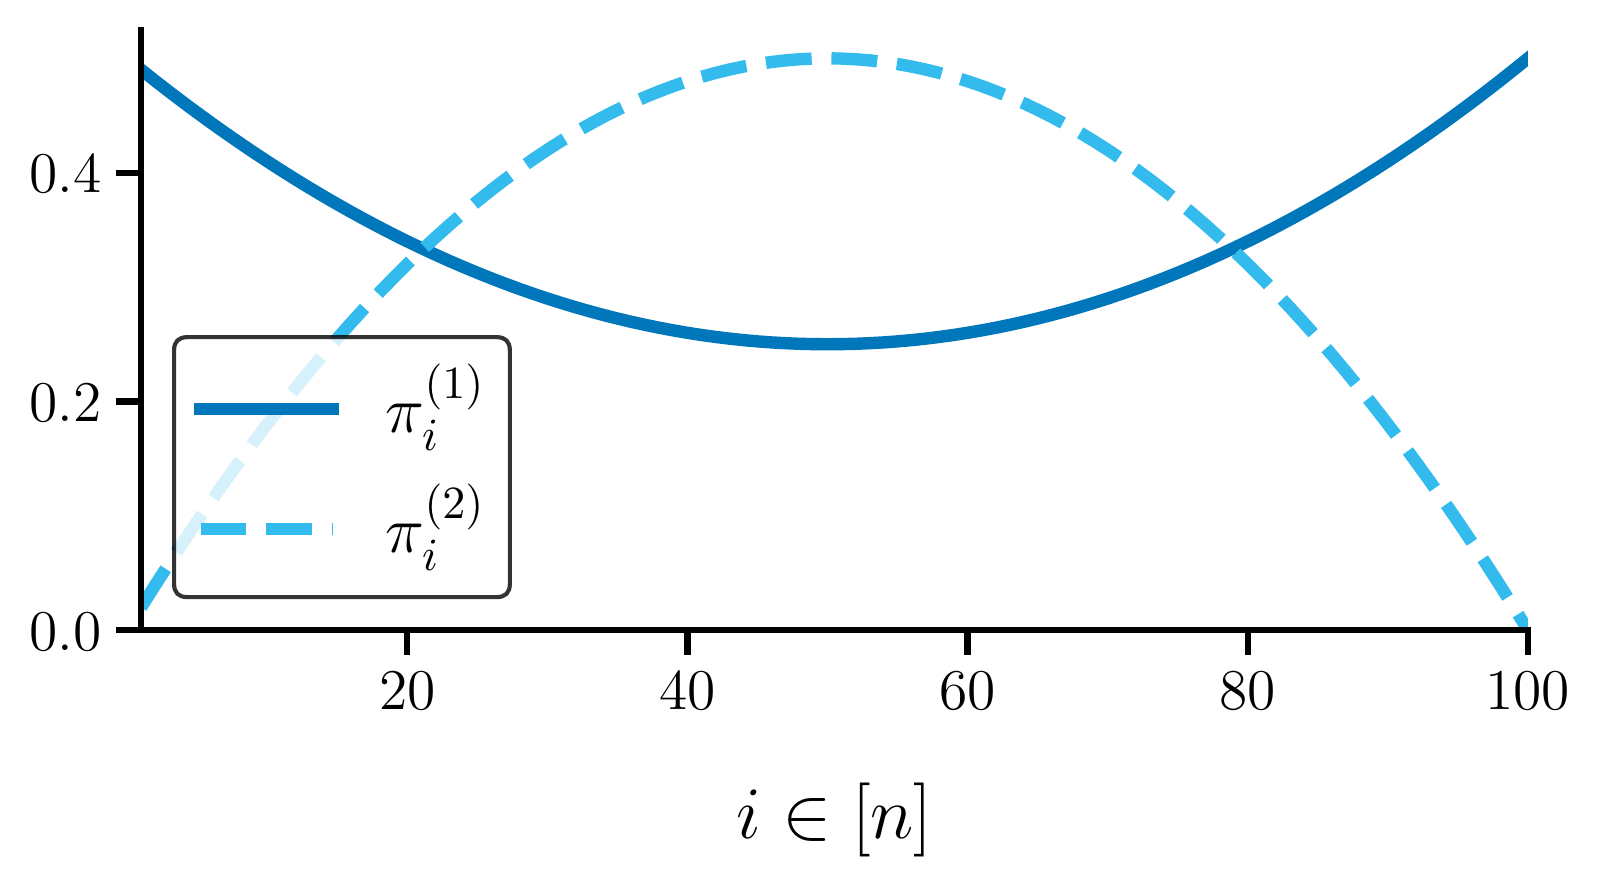

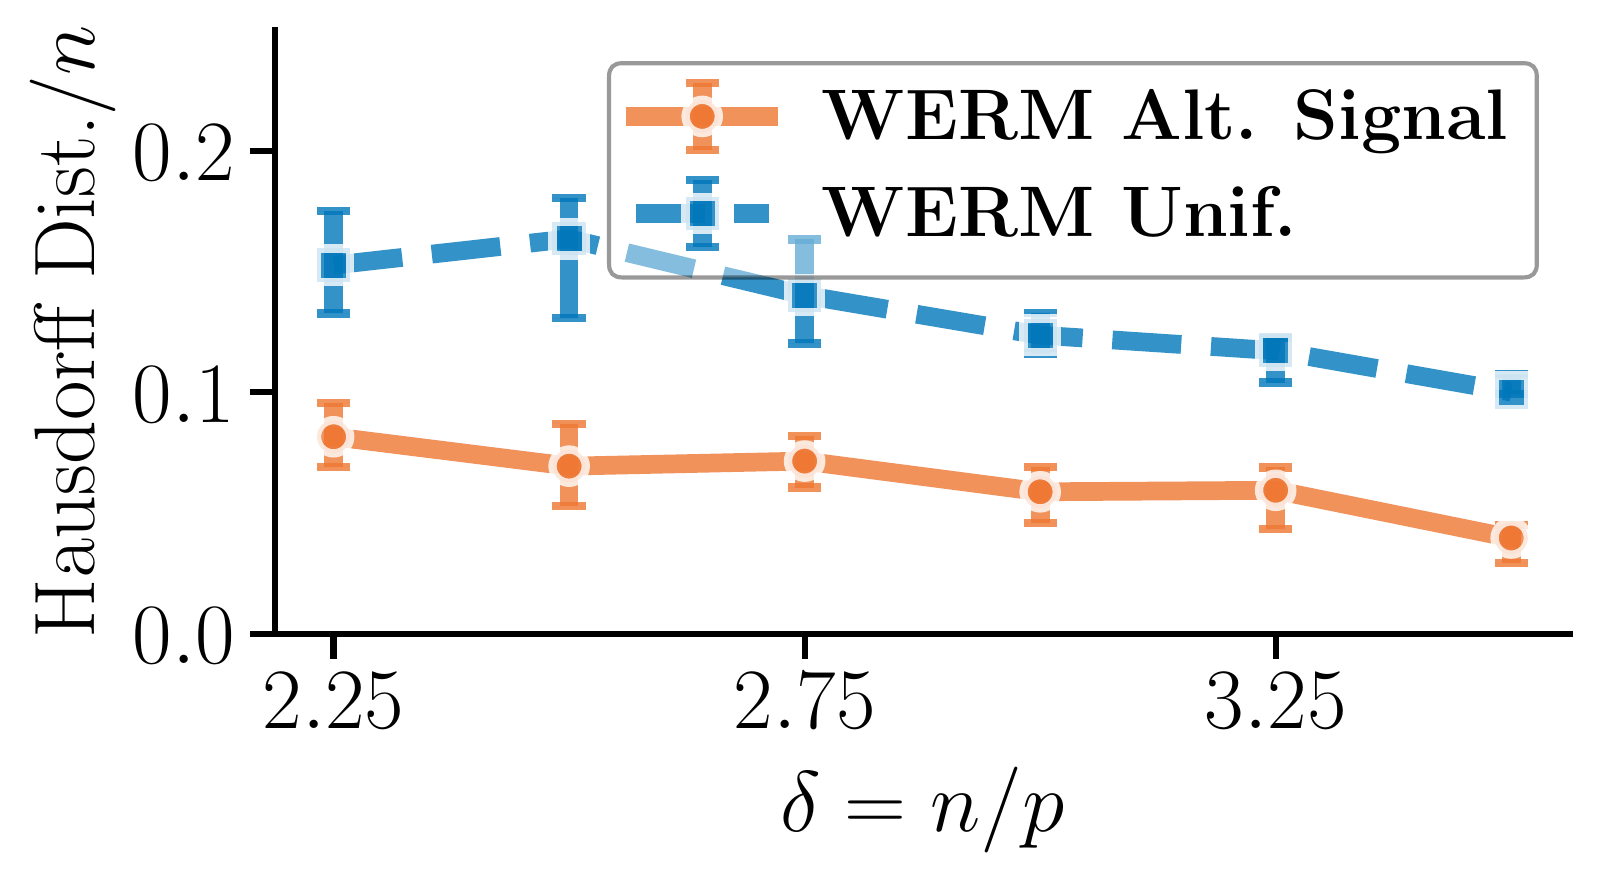

In [7]:
panels = ['figures/marginal_viz_L3_twostate.pdf', 'figures/WERM_SE_match_est_switchvsunif_huber_laplace_nopinorm_ERM-switch_Theory-switch_ERM-unif_Theory-unif_p800_L3_noisestd0.31622776601683794_seed42_deltas_2_2_2_3_3_3_location.pdf'] if REGENERATE_FIGURES else ['figures/figure_12/panel_01.pdf', 'figures/figure_12/panel_02.pdf']
show_panels(panels)


## Figure 13

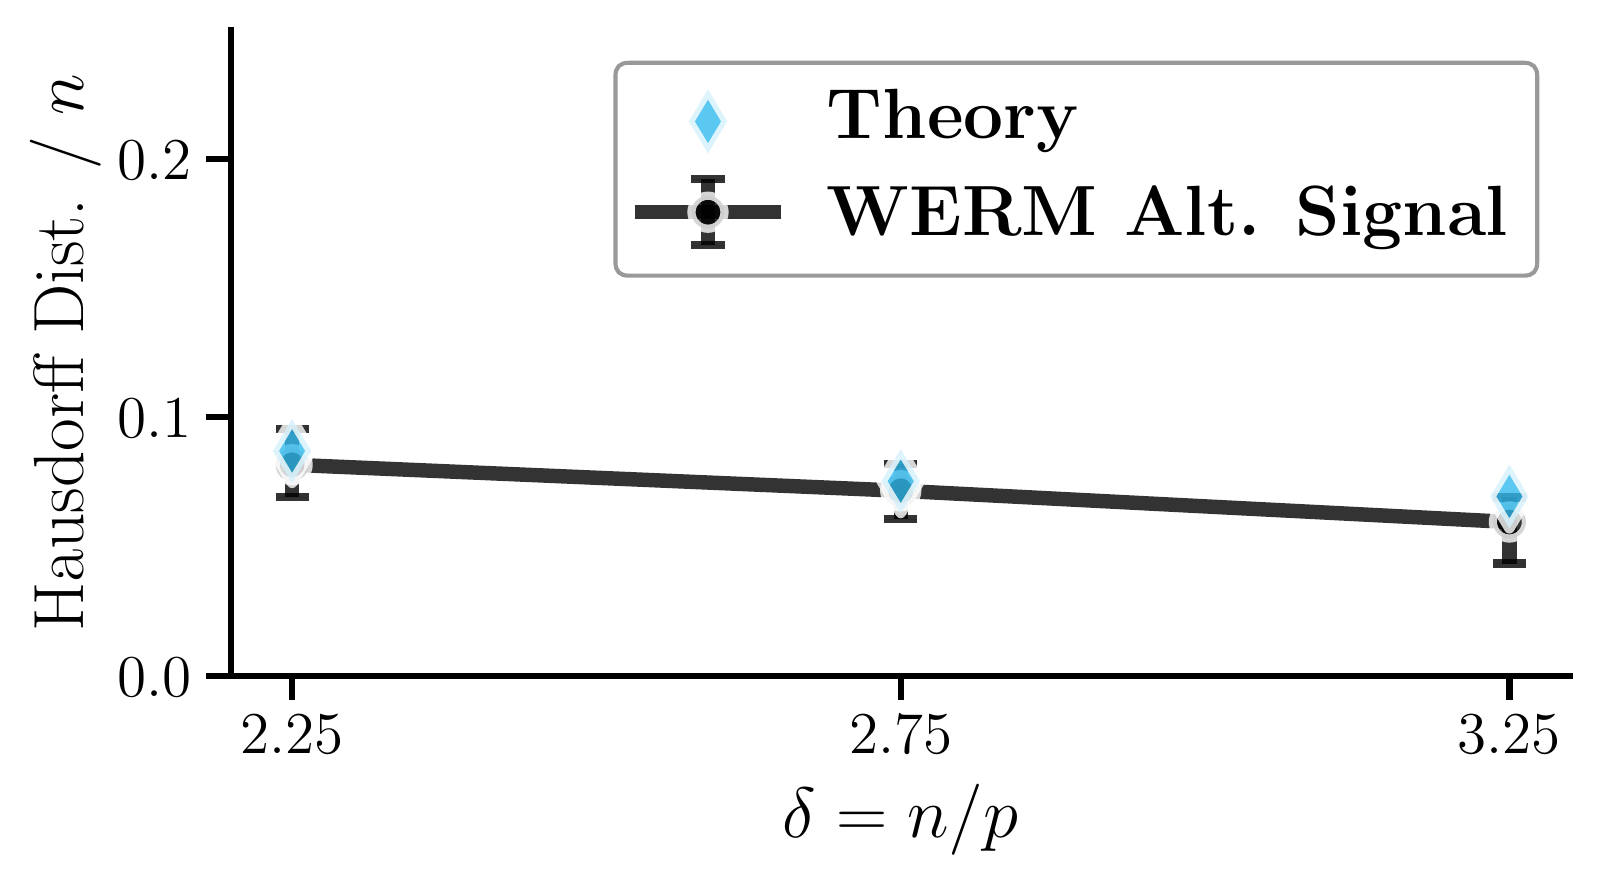

In [8]:
panels = ['figures/WERM_SE_match_est_switchvsunif_huber_laplace_nopinorm_ERM-switch_Theory-switch_ERM-unif_Theory-unif_p800_L3_noisestd0.31622776601683794_seed42_deltas_2_2_2_3_3_3_location_SEmatch.pdf'] if REGENERATE_FIGURES else ['figures/figure_13/panel_01.pdf']
show_panels(panels)
